# 08 · Out of platform: the full matrix

Trained on any subset of TikTok, YouTube, X, tested on a platform left out. Strict: every fold's test brands are removed from training, also on the other platforms. The diagonal (trained on the same platform) uses plain brand-grouped CV.

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "reach_samples_students.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
import eda_utils as eu, modeling as mo, transfer_matrix as tm

FIG = ROOT / "figures"; plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 220, "display.max_columns", 30, "display.max_colwidth", 80)

In [2]:
f, text, meta = tm.load(ROOT); f.join(meta[['platform']]).groupby('platform').mean().round(2)

,log_followers,na_followers,log_likes,na_likes,log_comments,na_comments,log_shares,na_shares
platform,,,,,,,,
facebook,3.41,0.27,1.89,0.00,0.02,0.00,0.72,0.00
instagram,0.32,0.92,1.11,0.00,0.29,0.00,0.00,1.00
tiktok,3.09,0.00,3.73,0.00,1.33,0.00,1.37,0.00
twitter,2.57,0.00,0.44,0.00,0.16,0.69,0.12,0.00
youtube,4.36,0.00,2.41,0.05,1.18,0.09,0.00,0.41


## 1 · The matrix
Six models, three feature sets, twelve pairings.

In [3]:
res, preds = tm.matrix(f, meta); res.round(3).head(12)

ridge done


random forest done


extra trees done


boosting (sklearn) done


LightGBM done


CatBoost done


,model,features,source,target,kind,MAE,low,high,bias,MAE no bias,spearman,n
0,ridge,reactions,tiktok,tiktok,in-platform,0.299,0.288,0.312,-0.000,0.299,0.867,2491
1,ridge,reactions,youtube,tiktok,1 source(s),0.300,0.288,0.313,0.007,0.300,0.862,2491
2,ridge,reactions,twitter,tiktok,1 source(s),0.528,0.510,0.545,-0.289,0.466,0.867,2491
3,ridge,reactions,youtube+twitter,tiktok,2 source(s),0.313,0.302,0.326,0.029,0.313,0.867,2491
4,ridge,reactions,youtube,youtube,in-platform,0.618,0.592,0.648,0.000,0.613,0.629,2441
5,ridge,reactions,tiktok,youtube,1 source(s),0.610,0.584,0.641,0.054,0.609,0.633,2441
6,ridge,reactions,twitter,youtube,1 source(s),0.740,0.705,0.780,0.008,0.714,0.637,2441
7,ridge,reactions,tiktok+twitter,youtube,2 source(s),0.612,0.581,0.644,0.208,0.610,0.627,2441
8,ridge,reactions,twitter,twitter,in-platform,0.519,0.498,0.542,-0.001,0.517,0.469,1803
9,ridge,reactions,tiktok,twitter,1 source(s),0.617,0.592,0.638,-0.336,0.540,0.486,1803


In [4]:
avg = res[res.kind != "in-platform"].groupby(["features", "model"]).MAE.mean().unstack(0).round(3); own = res[res.kind == "in-platform"].groupby(["features", "model"]).MAE.mean().unstack(0).round(3)
print("mean MAE across platforms, trained elsewhere"); display(avg.sort_values(avg.columns[0])); print("mean MAE, trained on the same platform"); display(own.sort_values(own.columns[0]))

mean MAE across platforms, trained elsewhere


features,reactions,reactions + followers,reactions + followers + shares + flags
model,,,
ridge,0.559,0.567,0.578
extra trees,0.574,0.531,0.550
CatBoost,0.581,0.560,0.587
random forest,0.583,0.559,0.572
boosting (sklearn),0.591,0.562,0.583
LightGBM,0.592,0.561,0.581


mean MAE, trained on the same platform


features,reactions,reactions + followers,reactions + followers + shares + flags
model,,,
extra trees,0.462,0.424,0.405
random forest,0.466,0.438,0.417
CatBoost,0.467,0.433,0.411
LightGBM,0.468,0.441,0.419
boosting (sklearn),0.469,0.442,0.420
ridge,0.479,0.450,0.437


In [5]:
FN = "reactions"; two = res[(res.features == FN) & (res.kind == "2 source(s)")].groupby("model").MAE.mean().sort_values(); MN = two.index[0]; print("best model across the three two-source moves:", MN); display(two.round(3))
res[(res.model == MN) & (res.features == FN)][["source", "target", "kind", "MAE", "low", "high", "bias", "MAE no bias", "spearman", "n"]].round(3)

best model across the three two-source moves: ridge


model
ridge                 0.525
extra trees           0.568
CatBoost              0.569
random forest         0.574
boosting (sklearn)    0.577
LightGBM              0.579
Name: MAE, dtype: float64

,source,target,kind,MAE,low,high,bias,MAE no bias,spearman,n
0,tiktok,tiktok,in-platform,0.299,0.288,0.312,-0.000,0.299,0.867,2491
1,youtube,tiktok,1 source(s),0.300,0.288,0.313,0.007,0.300,0.862,2491
2,twitter,tiktok,1 source(s),0.528,0.510,0.545,-0.289,0.466,0.867,2491
3,youtube+twitter,tiktok,2 source(s),0.313,0.302,0.326,0.029,0.313,0.867,2491
4,youtube,youtube,in-platform,0.618,0.592,0.648,0.000,0.613,0.629,2441
5,tiktok,youtube,1 source(s),0.610,0.584,0.641,0.054,0.609,0.633,2441
6,twitter,youtube,1 source(s),0.740,0.705,0.780,0.008,0.714,0.637,2441
7,tiktok+twitter,youtube,2 source(s),0.612,0.581,0.644,0.208,0.610,0.627,2441
8,twitter,twitter,in-platform,0.519,0.498,0.542,-0.001,0.517,0.469,1803
9,tiktok,twitter,1 source(s),0.617,0.592,0.638,-0.336,0.540,0.486,1803


## 2 · Main pictures

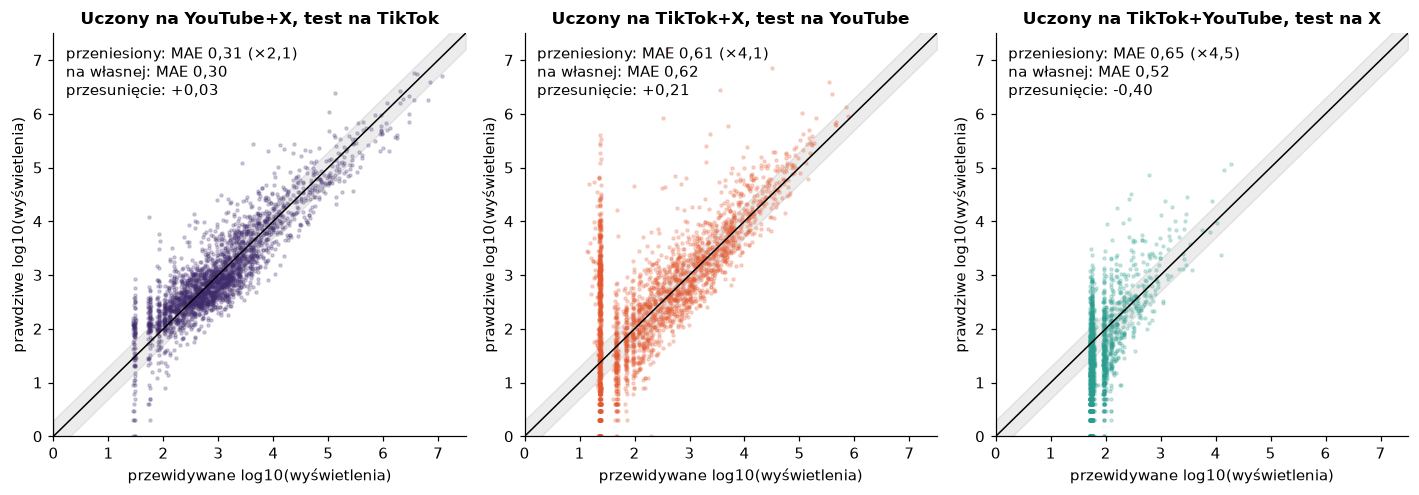

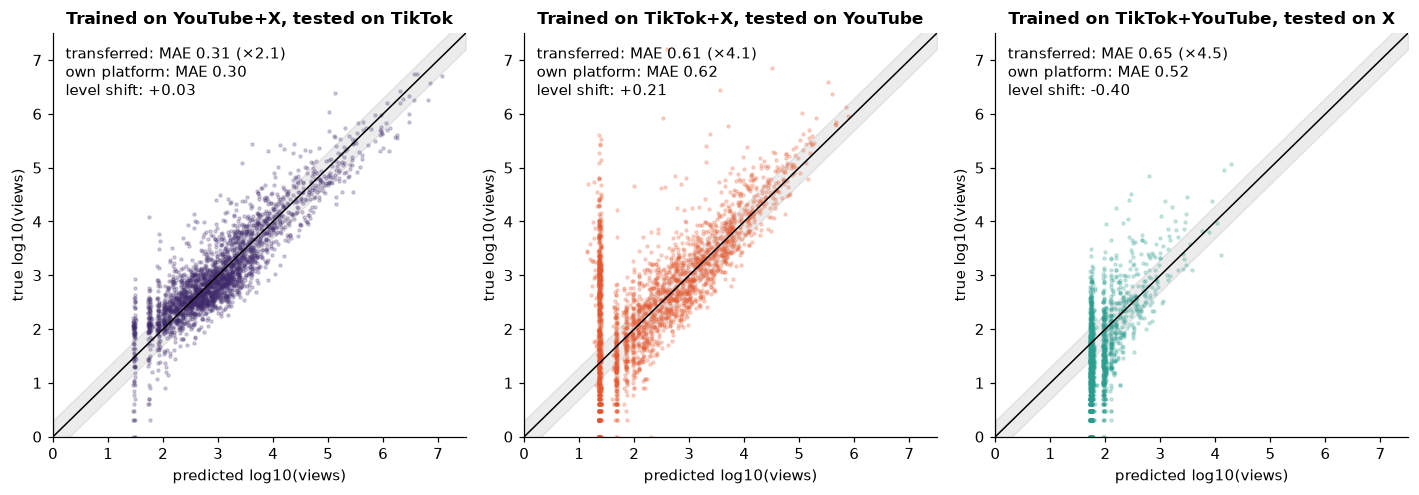

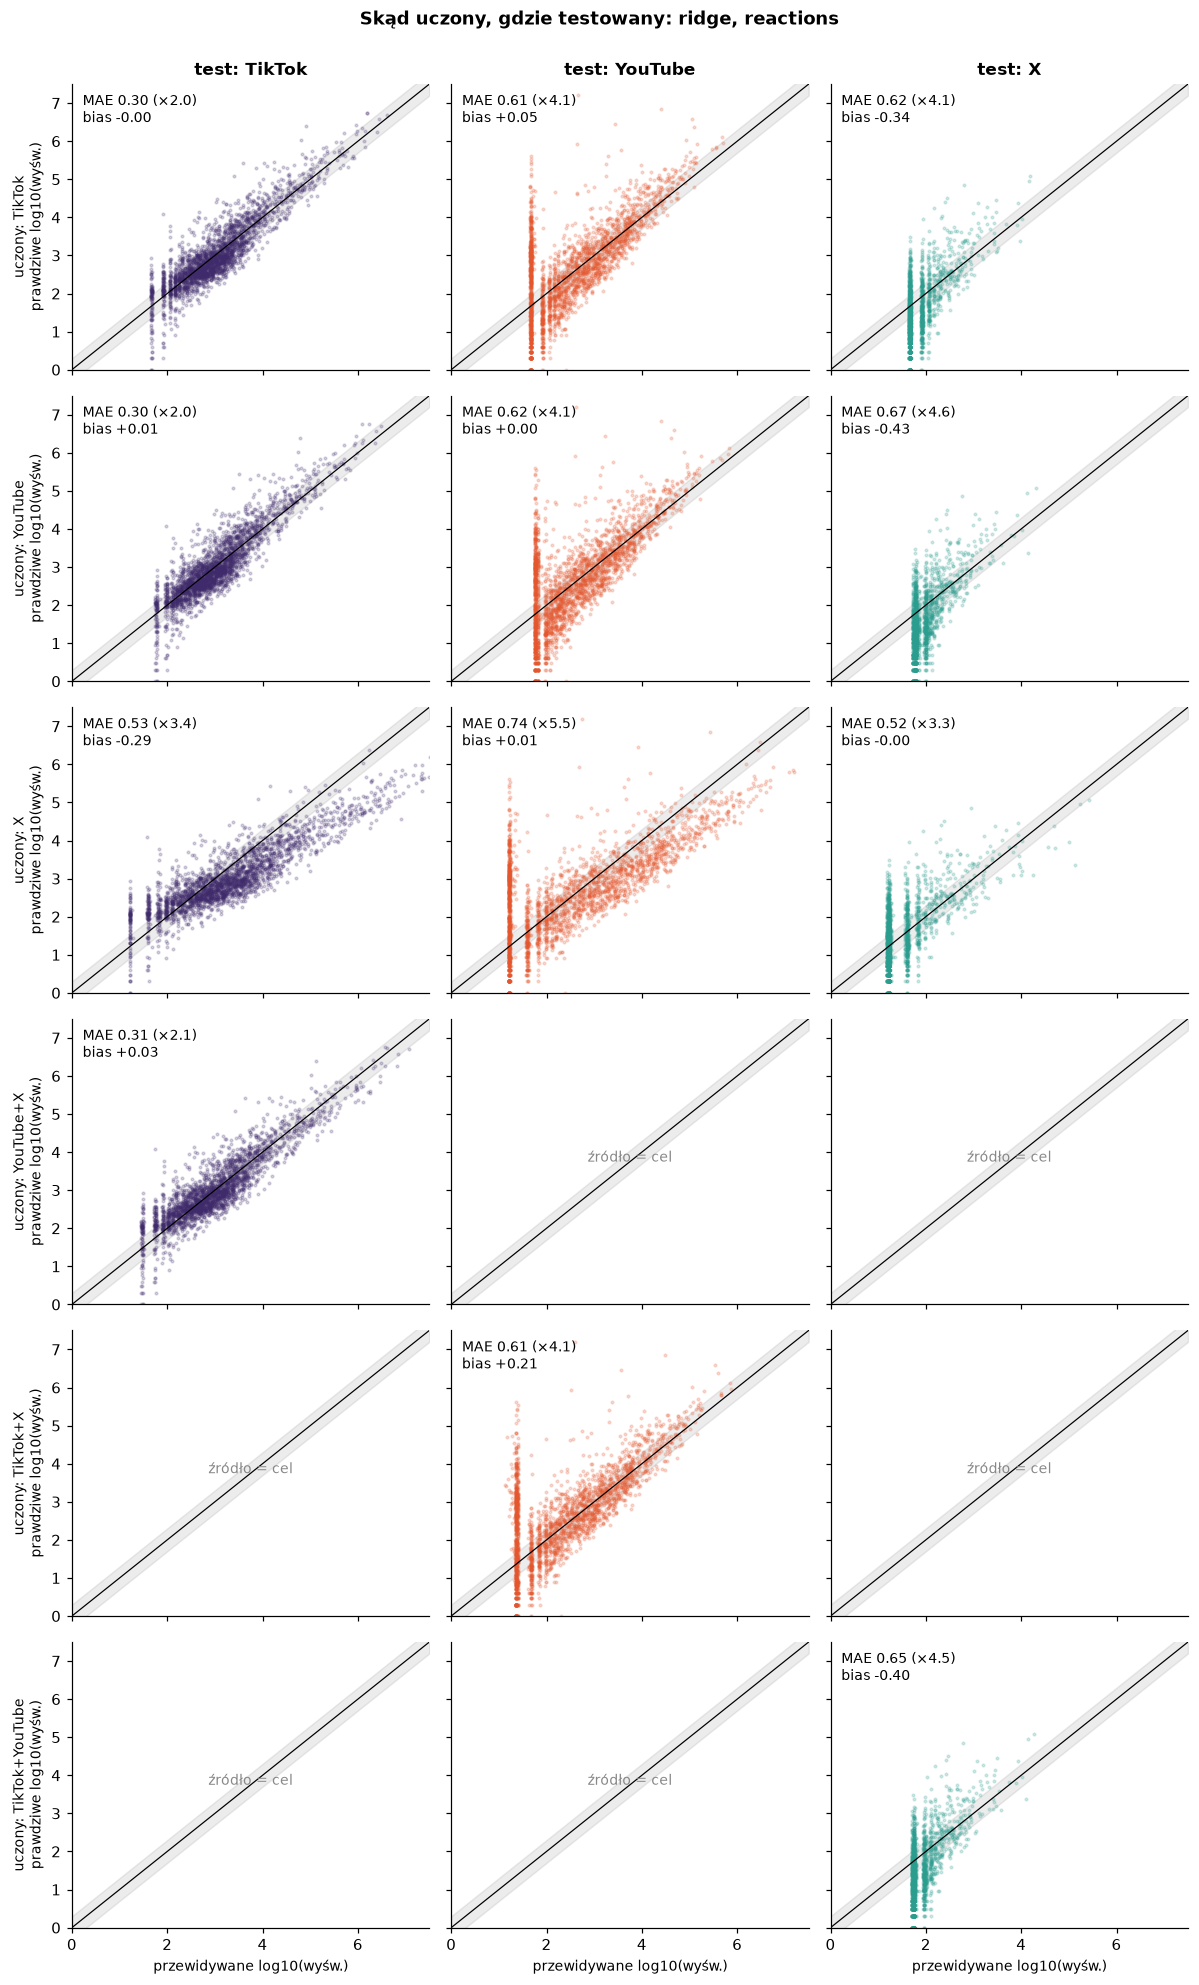

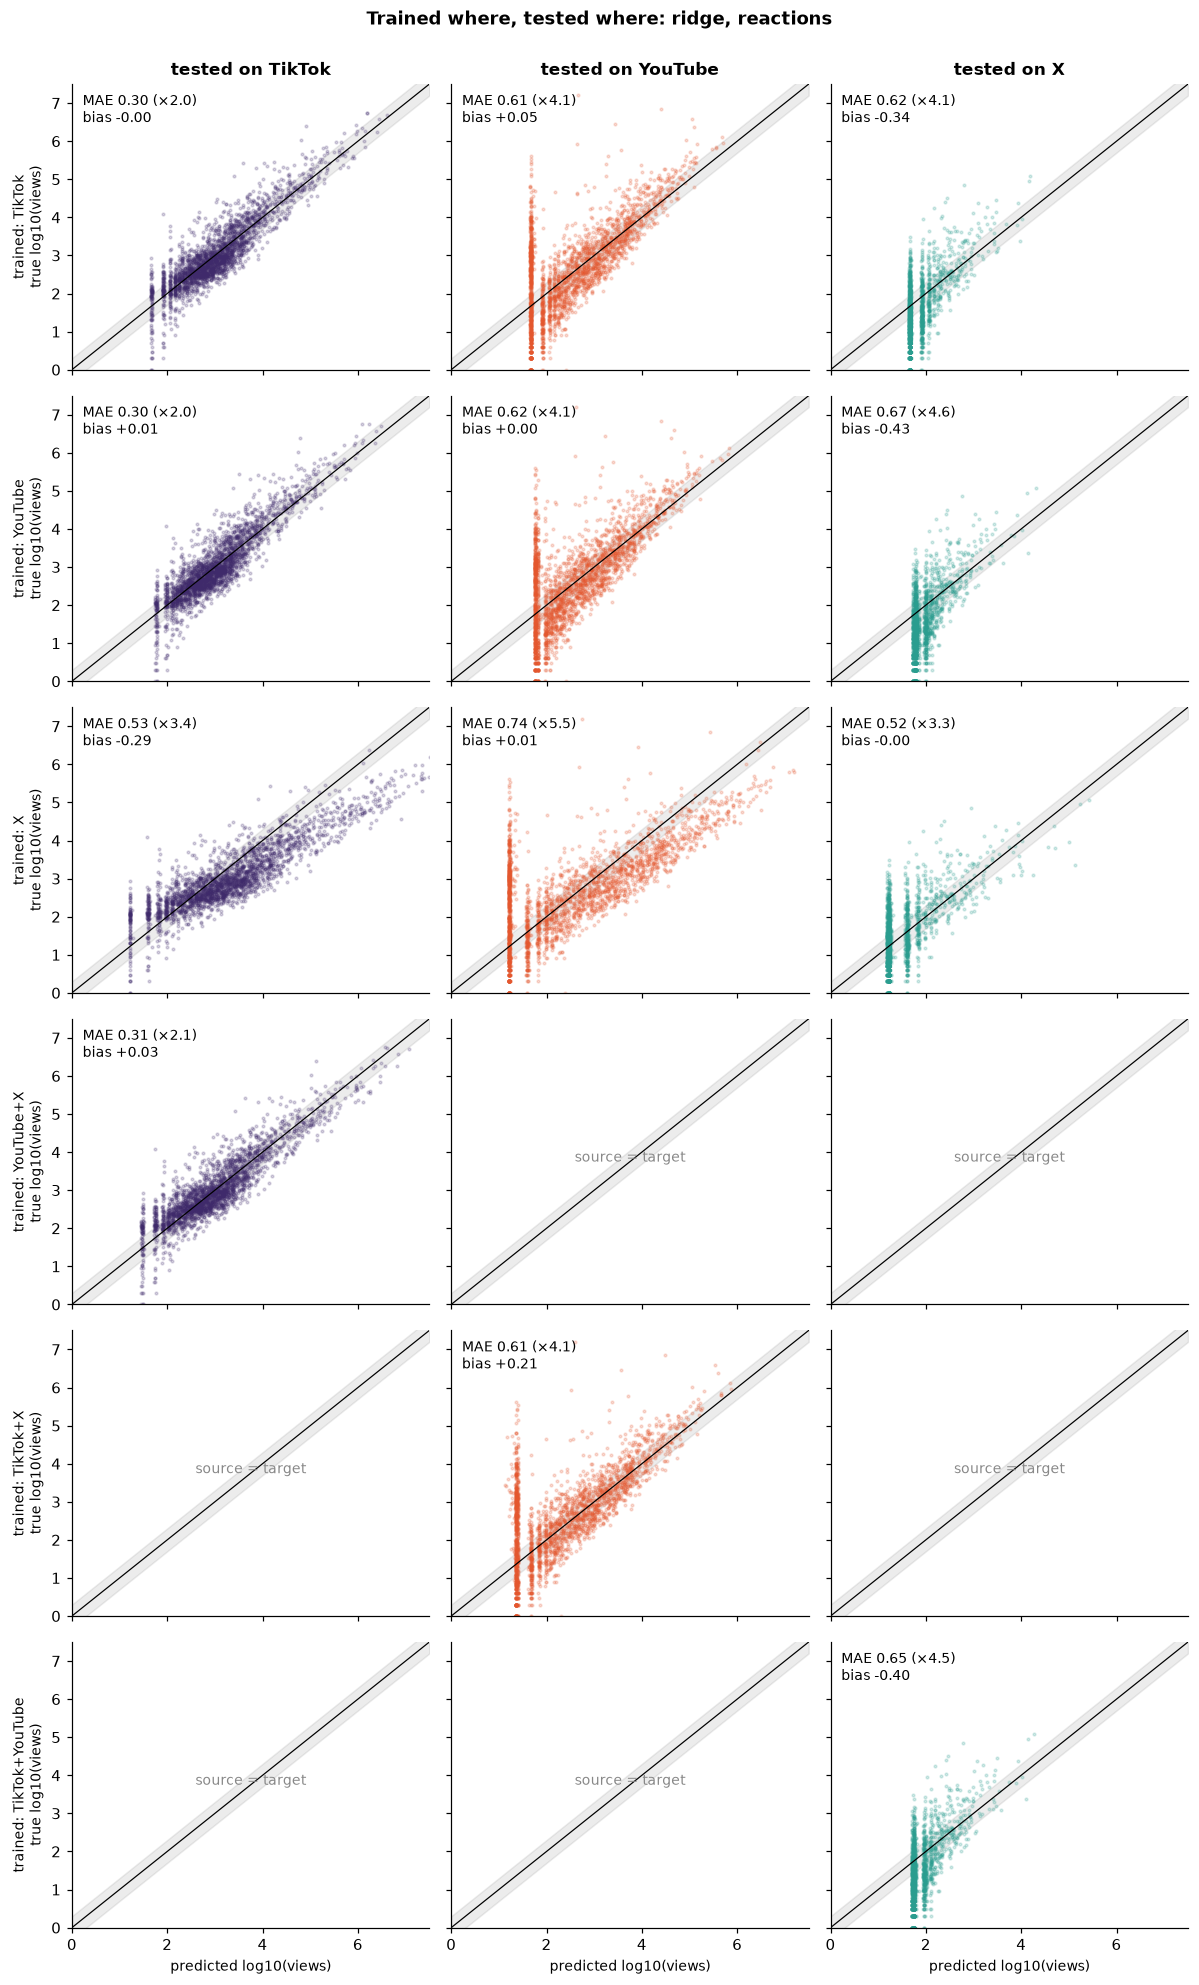

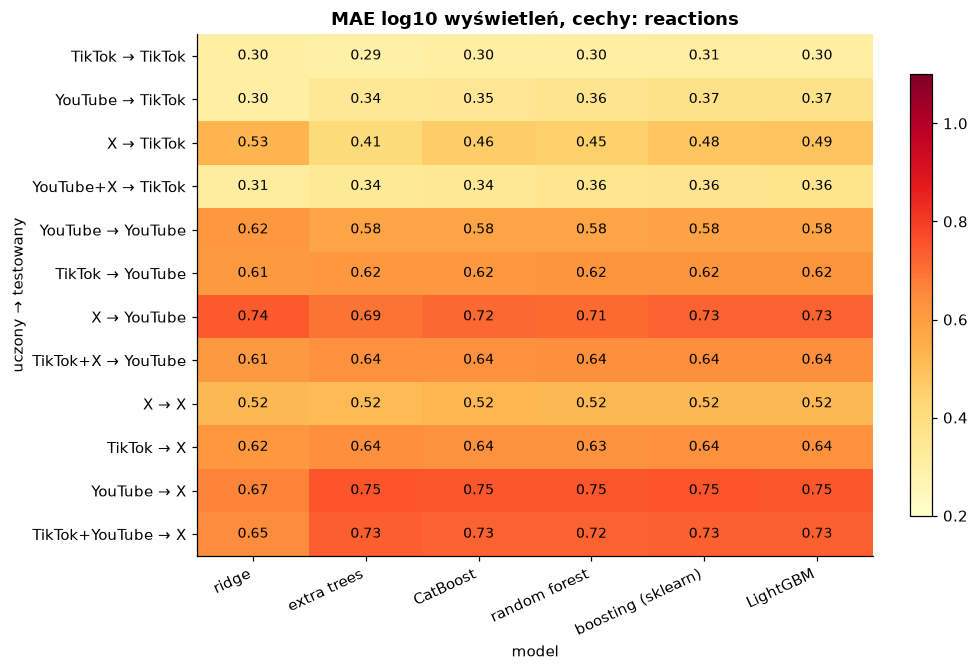

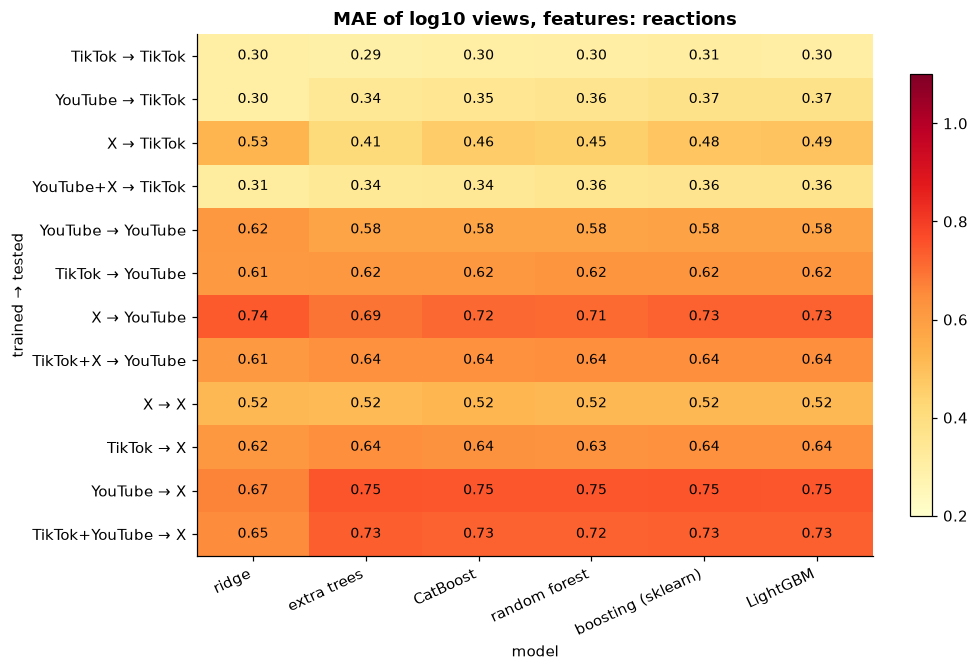

In [6]:
for l in ("pl", "en"): tm.plot_lopo(preds, meta, MN, FN, FIG / f"lopo_{l}.png", l)
for l in ("pl", "en"): tm.plot_grid(preds, meta, MN, FN, FIG / f"transfer_grid_{l}.png", l)
for l in ("pl", "en"): tm.plot_heat(res, FN, FIG / f"transfer_heat_{l}.png", l)

## 3 · Does removing test brands from other platforms matter?

In [7]:
bf = tm.brand_filter_effect(f, meta, tm.models()[MN], tm.FEATURE_SETS[FN]); bf.round(3)

,held-out platform,brands removed from training,brands kept
0,TikTok,0.313,0.313
1,YouTube,0.612,0.612
2,X (Twitter),0.649,0.650


## 4 · Tuning for the move
Defaults; settings best inside the source platforms; settings best when crossing between the two sources (leave-one-source-out). No view from the target is used in the choice.

In [8]:
tt = tm.tune_for_transfer(f, meta, tm.FEATURE_SETS[FN]); tt.pivot_table(index=["model", "settings"], columns="held-out platform", values="MAE").round(3)

TikTok ridge done


TikTok extra trees done


TikTok boosting (sklearn) done


TikTok LightGBM done


TikTok CatBoost done


YouTube ridge done


... (6 outputs left out)

X (Twitter) boosting (sklearn) done


X (Twitter) LightGBM done


X (Twitter) CatBoost done


held-out platform                        TikTok  X (Twitter)  YouTube
model              settings                                          
CatBoost           default                0.344        0.727    0.637
                   tuned across sources   0.334        0.738    0.633
                   tuned inside sources   0.334        0.711    0.637
LightGBM           default                0.364        0.730    0.642
                   tuned across sources   0.360        0.756    0.642
                   tuned inside sources   0.356        0.734    0.639
boosting (sklearn) default                0.361        0.729    0.640
                   tuned across sources   0.356        0.741    0.639
                   tuned inside sources   0.344        0.741    0.635
extra trees        default                0.387        0.729    0.652
                   tuned across sources   0.338        0.763    0.632
                   tuned inside sources   0.338        0.763    0.629
ridge              default                0.313        0.649    0.612
                   tuned across sources   0.337        0.649    0.606
                   tuned inside sources   0.313        0.649    0.610

## 5 · Can our labels help the move?
Facebook and Instagram have labels too, so a correction based on labels could be used there.

In [9]:
la = tm.label_adaptation(f, meta, tm.models()['LightGBM'], tm.FEATURE_SETS[FN]); la[['held-out platform', 'variant', 'MAE', 'low', 'high', 'bias']].round(3)

,held-out platform,variant,MAE,low,high,bias
0,TikTok,no labels,0.364,0.351,0.377,-0.000
1,TikTok,source reweighted to target's type mix,0.364,0.351,0.377,-0.009
2,TikTok,type as a feature,0.360,0.347,0.372,-0.011
3,YouTube,no labels,0.642,0.610,0.678,0.192
4,YouTube,source reweighted to target's type mix,0.644,0.614,0.679,0.173
5,YouTube,type as a feature,0.634,0.605,0.669,0.165
6,X (Twitter),no labels,0.730,0.700,0.753,-0.478
7,X (Twitter),source reweighted to target's type mix,0.755,0.724,0.779,-0.515
8,X (Twitter),type as a feature,0.748,0.717,0.772,-0.513


## 6 · Would a few posts with real views fix the level?
The claim in our email to Brand24: tens of posts would be enough. Each curve shifts all predictions by the median error of n target posts and scores on the rest.

,n,median,low,high,uncalibrated,oracle,platform
0,5,0.331,0.313,0.456,0.313,0.313,tiktok
1,10,0.321,0.313,0.386,0.313,0.313,tiktok
2,25,0.317,0.313,0.348,0.313,0.313,tiktok
3,50,0.315,0.312,0.328,0.313,0.313,tiktok
4,100,0.314,0.312,0.321,0.313,0.313,tiktok
5,200,0.314,0.311,0.318,0.313,0.313,tiktok
6,500,0.313,0.309,0.318,0.313,0.313,tiktok


,n,median,low,high,uncalibrated,oracle,platform
0,5,0.640,0.611,0.958,0.612,0.61,youtube
1,10,0.624,0.610,0.733,0.612,0.61,youtube
2,25,0.617,0.609,0.670,0.612,0.61,youtube
3,50,0.614,0.609,0.637,0.612,0.61,youtube
4,100,0.612,0.607,0.625,0.612,0.61,youtube
5,200,0.612,0.605,0.620,0.612,0.61,youtube
6,500,0.611,0.600,0.622,0.612,0.61,youtube


,n,median,low,high,uncalibrated,oracle,platform
0,5,0.584,0.545,0.876,0.649,0.544,twitter
1,10,0.563,0.545,0.681,0.649,0.544,twitter
2,25,0.553,0.544,0.605,0.649,0.544,twitter
3,50,0.549,0.544,0.574,0.649,0.544,twitter
4,100,0.547,0.542,0.559,0.649,0.544,twitter
5,200,0.546,0.540,0.554,0.649,0.544,twitter
6,500,0.546,0.536,0.556,0.649,0.544,twitter


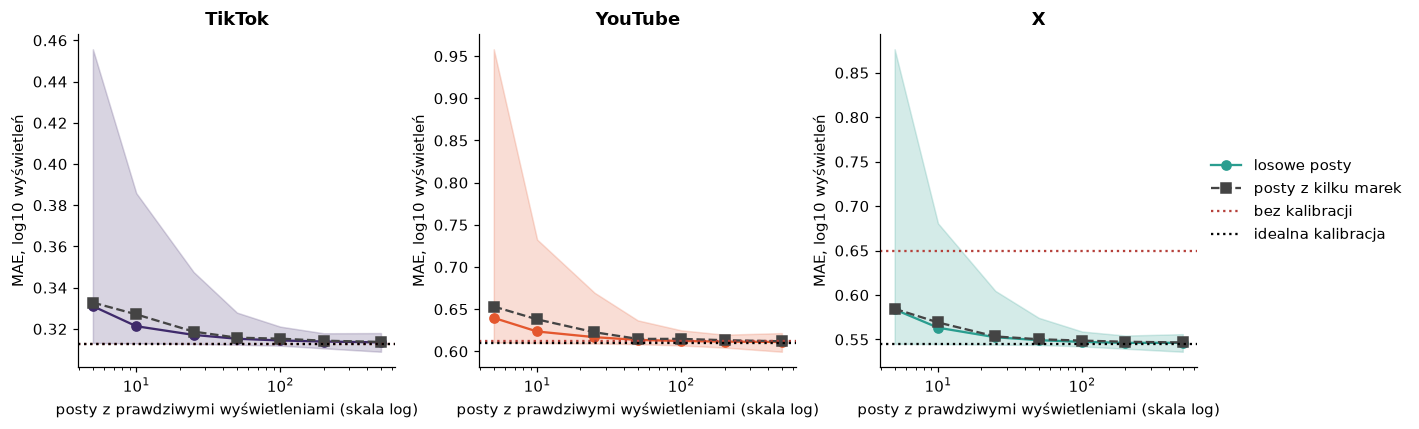

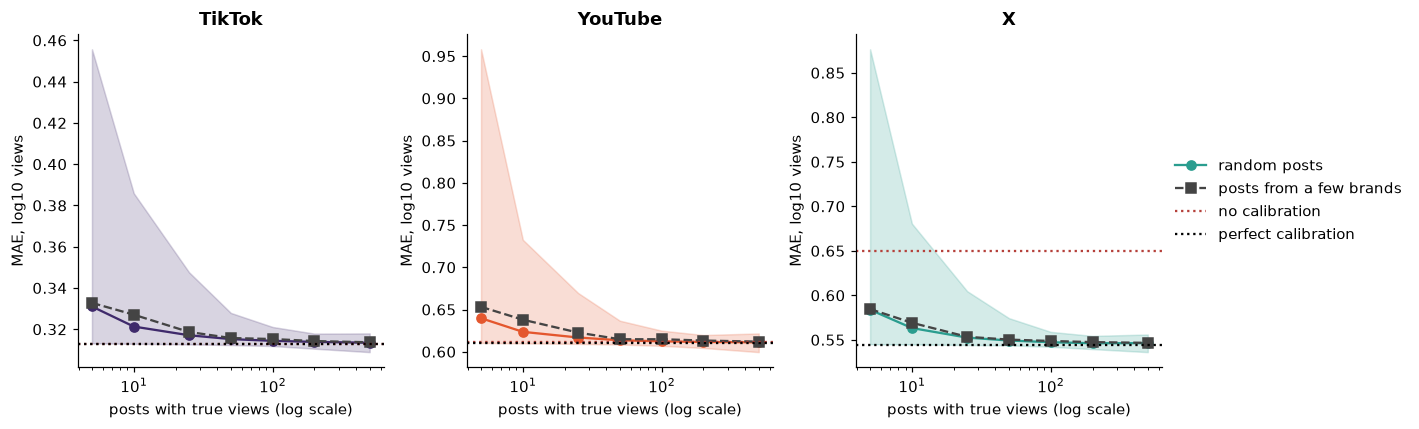

In [10]:
curves = {}
for t in tm.KNOWN:
    p = preds[(MN, FN, tuple(x for x in tm.KNOWN if x != t), t)]; curves[t] = {"random": tm.calibration_curve(p, meta), "brands": tm.calibration_curve(p, meta, per_brand=True, reps=200)}; display(curves[t]["random"].round(3).assign(platform=t))
for l in ("pl", "en"): tm.plot_calibration(curves, FIG / f"calibration_{l}.png", l)

## 7 · Facebook and Instagram: how much does the estimate depend on the source?
Nothing can be checked here. The spread between sources is a lower bound on the uncertainty about the level.

In [11]:
us = tm.unknown_sensitivity(f, meta, tm.models()[MN], tm.FEATURE_SETS[FN]); display(us.round(2)); sp = us.groupby("platform")["median log10 views"].agg(["min", "max"]).assign(spread=lambda d: d["max"] - d["min"], factor=lambda d: 10 ** (d["max"] - d["min"])); sp.round(2)

,source,platform,median log10 views,median Brand24 reach
0,TikTok,Facebook,2.16,3.46
1,TikTok,Instagram,1.91,1.90
2,YouTube,Facebook,2.20,3.46
3,YouTube,Instagram,1.98,1.90
4,X (Twitter),Facebook,1.98,3.46
5,X (Twitter),Instagram,1.60,1.90
6,TikTok+YouTube,Facebook,2.19,3.46
7,TikTok+YouTube,Instagram,1.97,1.90
8,TikTok+X (Twitter),Facebook,1.98,3.46
9,TikTok+X (Twitter),Instagram,1.68,1.90


,min,max,spread,factor
platform,,,,
Facebook,1.98,2.20,0.22,1.65
Instagram,1.60,1.98,0.39,2.44


## Takeaways
- **Level shift, not lost order:** trained on two platforms, ridge on likes + comments gives TikTok 0.31, YouTube 0.61, X 0.65, against 0.30, 0.62, 0.52 on the same platform. Rank correlation barely moves (0.87, 0.63, 0.50 vs 0.87, 0.63, 0.47). Only X pays, because its level is shifted by -0.40 (factor 2.5).
- **Simple beats complex across platforms** with reactions only: boosters lose 0.03-0.08 to ridge when moved. Adding followers helps X (0.65 to about 0.57) but hurts ridge on TikTok (0.31 to 0.47), so more columns are not safer.
- **Tuning for the move does not help:** no way of choosing settings improves the error consistently; ridge's default stays near the best.
- **Our labels do not help the move:** reweighting or adding the type changes the error by less than 0.03, in both directions.
- **Removing test brands from other platforms changes nothing** (at most 0.001), so the earlier test was not inflated by brand overlap.
- **Calibration claim holds on known platforms:** 25-50 posts with real views bring the error on X from 0.65 to about 0.55, close to the 0.54 of perfect calibration, also when the posts come from a few brands. It goes no lower, and TikTok and YouTube gain nothing because their median error is already near zero.
- **Facebook and Instagram:** the median estimate moves by a factor of 1.7 and 2.4 depending on the source. This is not a measured error; nothing here can be checked without real views on those platforms.

In [12]:
json.dump({"best_model": MN, "features": FN, "matrix": res.to_dict("records"), "brand_filter": bf.to_dict("records"), "tuning": tt.to_dict("records"), "labels": la.to_dict("records"), "calibration": {t: {k: v.to_dict("records") for k, v in c.items()} for t, c in curves.items()}, "unknown": us.to_dict("records"), "unknown_spread": sp.reset_index().to_dict("records")}, open(ROOT / "data" / "processed" / "transfer_numbers.json", "w"), indent=1, default=float)